# Event Streaming with Apache Kafka

Batch pipelines (M11) move data on a schedule. **Event streaming** moves each event as it happens: a payment, a click,
a sensor reading, a taxi trip. **Apache Kafka** is the standard platform for this. It stores events in an ordered,
durable log, many applications can write to it, and many can read from it at their own speed.

**After this lesson you can:**

1. Explain topics, partitions, offsets, keys, consumer groups and retention.
2. Produce events with batching and compression, and measure the throughput.
3. Scale consumption with consumer groups, and measure consumer lag.
4. Choose a delivery guarantee: at-most-once, at-least-once, exactly-once (idempotent producer, transactions).

**Data:** NYC taxi trips (January 2024), replayed as events.
**Services:** `docker compose -f docker/compose.yml --profile streaming up -d kafka` starts a one-node Kafka 3.9
in KRaft mode (no ZooKeeper) on `localhost:9092`.

In [1]:
import json
import sys
import threading
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from confluent_kafka import Consumer, KafkaException, Producer, TopicPartition
from confluent_kafka.admin import AdminClient, NewTopic

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
BOOTSTRAP = "localhost:9092"
datasets.ensure_service("streaming", "kafka")
admin = AdminClient({"bootstrap.servers": BOOTSTRAP})

def fresh_topic(name: str, partitions: int, **config) -> None:
    """(Re)create a topic so that every run of the notebook starts from an empty log."""
    if name in admin.list_topics(timeout=10).topics:
        admin.delete_topics([name])[name].result()
        while name in admin.list_topics(timeout=10).topics:
            time.sleep(0.5)
    while True:                                  # deletion is asynchronous: retry until the name is free
        try:
            admin.create_topics([NewTopic(name, partitions, 1, config=config)])[name].result()
            return
        except KafkaException as e:
            if "already exists" not in str(e) and "marked for deletion" not in str(e):
                raise
            time.sleep(0.5)

trips = pd.read_parquet(datasets.taxi("2024-01"),
                        columns=["tpep_pickup_datetime", "PULocationID", "DOLocationID", "trip_distance", "total_amount"])
trips = trips[(trips.tpep_pickup_datetime >= "2024-01-01") & (trips.tpep_pickup_datetime < "2024-02-01")]
trips = trips.sort_values("tpep_pickup_datetime").head(200_000).reset_index(drop=True)
trips["trip_id"] = trips.index
events = [json.dumps({"trip_id": int(r.trip_id), "pickup_at": r.tpep_pickup_datetime.isoformat(),
                      "pu_zone": int(r.PULocationID), "do_zone": int(r.DOLocationID),
                      "distance": float(r.trip_distance), "total": float(r.total_amount)}).encode()
          for r in trips.itertuples()]
print(f"broker: {list(admin.list_topics(timeout=10).brokers.values())}")
print(f"{len(events):,} trip events, average size {sum(map(len, events)) / len(events):.0f} bytes")
print(events[0].decode())

broker: [BrokerMetadata(1, localhost:9092)]
200,000 trip events, average size 119 bytes
{"trip_id": 0, "pickup_at": "2024-01-01T00:00:00", "pu_zone": 140, "do_zone": 140, "distance": 0.3, "total": 11.25}


## 1. The Log: Topics, Partitions, Offsets

| Concept | Meaning |
| :--- | :--- |
| **topic** | a named stream of events, e.g. `taxi-trips` |
| **partition** | a topic is split into ordered, append-only logs; partitions are the unit of parallelism |
| **offset** | the position of an event inside its partition (0, 1, 2, ...) |
| **key** | optional; events with the same key go to the same partition, so their order is kept |
| **retention** | events stay for a time or size limit (default 7 days), whether they were read or not |
| **consumer group** | consumers that share the work: each partition is read by one member of the group |

Kafka orders events **only inside a partition**. Choose the key so that the events that must stay in order share it
(here: the pickup zone).

The cell produces the 200,000 events four times, with different producer settings, and measures the throughput.
`linger.ms` lets the producer wait a few milliseconds to fill bigger batches; compression shrinks the batches.

                    setting  events/s  MB on disk
no batching, no compression     29994        53.6
               linger 20 ms     18365        52.9
         linger 20 ms + lz4     16972        14.5
        linger 20 ms + zstd     17469         8.8


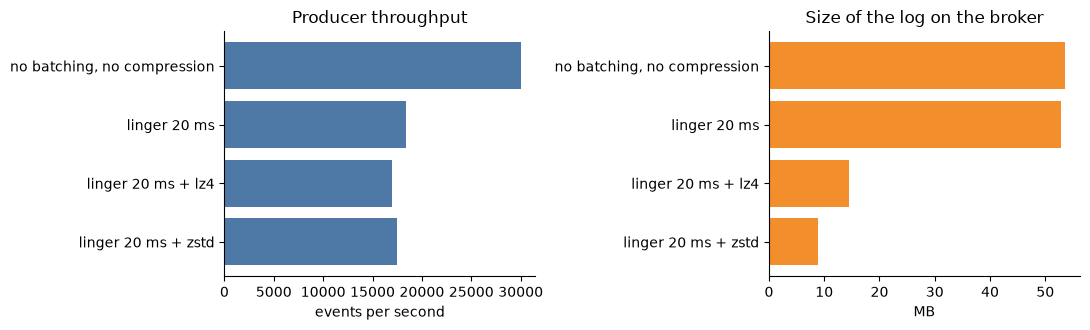

In [2]:
def produce_all(topic: str, **conf) -> dict:
    fresh_topic(topic, 6)
    p = Producer({"bootstrap.servers": BOOTSTRAP, **conf})
    t0 = time.perf_counter()
    for e, zone in zip(events, trips.PULocationID):
        while True:
            try:
                p.produce(topic, value=e, key=str(zone))
                break
            except BufferError:                 # local queue full: let the client send, then retry
                p.poll(0.05)
        p.poll(0)
    p.flush()
    secs = time.perf_counter() - t0
    return {"seconds": secs, "events/s": len(events) / secs}

def topic_bytes(topic: str) -> int:
    """Bytes in the topic's log segments (*.log); index files are preallocated, so they are skipped."""
    out = datasets.compose("exec", "-T", "kafka", "sh", "-c", f"cat /var/lib/kafka/data/{topic}-*/*.log | wc -c").stdout
    return int(out.strip() or 0)

settings = {"no batching, no compression": {"linger.ms": 0, "compression.type": "none"},
            "linger 20 ms":                {"linger.ms": 20, "compression.type": "none"},
            "linger 20 ms + lz4":          {"linger.ms": 20, "compression.type": "lz4"},
            "linger 20 ms + zstd":         {"linger.ms": 20, "compression.type": "zstd"}}
rows = []
for name, conf in settings.items():
    topic = "bench-" + name.split()[0] + "-" + conf["compression.type"] + "-" + str(conf["linger.ms"])
    r = produce_all(topic, **conf)
    time.sleep(1)
    rows.append({"setting": name, "events/s": round(r["events/s"]), "MB on disk": round(topic_bytes(topic) / 1e6, 1)})
bench = pd.DataFrame(rows)
print(bench.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].barh(bench.setting, bench["events/s"], color="#4E79A7"); ax[0].set(title="Producer throughput", xlabel="events per second")
ax[1].barh(bench.setting, bench["MB on disk"], color="#F28E2B"); ax[1].set(title="Size of the log on the broker", xlabel="MB")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.show()

*Insight: Here the Python loop limits the producer to roughly 20,000–30,000 events per second, so the clear effect is on size: lz4 makes the log about 3.7 times smaller and zstd about 6 times. Smaller batches on disk and on the network are what lets real clusters carry millions of events per second.*

## 2. Keys and Partitions

The default partitioner hashes the key (murmur2) and takes it modulo the number of partitions. All events of one zone
land in one partition; the partitions are uneven when a few keys are very frequent (a **hot key**).

events per partition: {0: 23427, 1: 35244, 2: 24727, 3: 52407, 4: 46925, 5: 17270}
zones that appear in more than one partition: 0
busiest pickup zones (events): {132: np.int64(15158), 161: np.int64(8708), 186: np.int64(7923)}


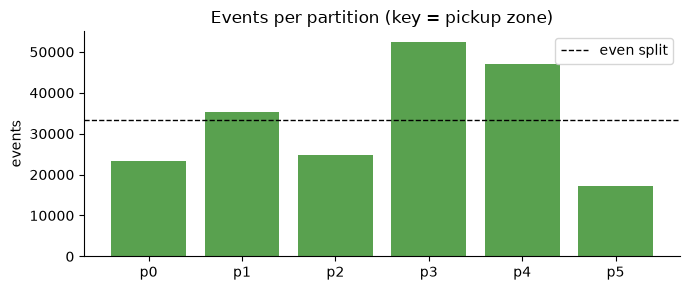

In [3]:
TOPIC = "taxi-trips"
p = Producer({"bootstrap.servers": BOOTSTRAP, "linger.ms": 20, "compression.type": "lz4"})
fresh_topic(TOPIC, 6)
for e, zone in zip(events, trips.PULocationID):
    while True:
        try:
            p.produce(TOPIC, value=e, key=str(zone)); break
        except BufferError:
            p.poll(0.05)
    p.poll(0)
p.flush()

c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": "inspect", "enable.auto.commit": False})
ends = {pt: c.get_watermark_offsets(TopicPartition(TOPIC, pt), timeout=10)[1] for pt in range(6)}

# read everything once and record partition and key of each event
c.assign([TopicPartition(TOPIC, pt, 0) for pt in range(6)])
seen, zone_parts = 0, {}
while seen < len(events):
    for m in c.consume(10_000, timeout=2):
        zone_parts.setdefault(m.key().decode(), set()).add(m.partition()); seen += 1
c.close()
print("events per partition:", ends)
print("zones that appear in more than one partition:", sum(len(v) > 1 for v in zone_parts.values()))
top = trips.PULocationID.value_counts().head(3)
print("busiest pickup zones (events):", dict(top))

plt.figure(figsize=(7, 3))
plt.bar([f"p{k}" for k in ends], ends.values(), color="#59A14F")
plt.axhline(len(events) / 6, color="black", ls="--", lw=1, label="even split")
plt.title("Events per partition (key = pickup zone)"); plt.ylabel("events"); plt.legend(); plt.tight_layout(); plt.show()

*Insight: A key gives order per key, not balance. Airport zones and Midtown create hot keys, so some partitions carry more events than others; a consumer of a hot partition becomes the bottleneck.*

## 3. Consumer Groups and Lag

Consumers with the same `group.id` split the partitions between them. The cell reads the whole topic with groups of
1, 2, 3 and 6 consumers (threads), and records how many partitions and events each member got. Each consumer also
"works" on every batch, like a write to a database (100 µs of waiting per event, so one consumer needs at
least 20 s for the whole topic).

 consumers  member  partitions  events  seconds
         1       0           6  200000     20.3
         2       0           2   58671     15.0
         2       1           4  141329     15.0
         3       0           2   64195      8.5
         3       1           2   77134      8.5
         3       2           2   58671      8.5
         6       0           1   35244      9.0
         6       1           1   24727      9.0
         6       2           1   46925      9.0
         6       3           1   17270      9.0
         6       4           1   52407      9.0
         6       5           1   23427      9.0

           seconds  max_events_per_member
consumers                                
1             20.3                 200000
2             15.0                 141329
3              8.5                  77134
6              9.0                  52407


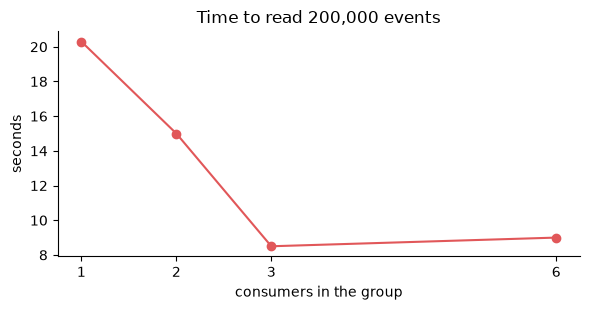

In [4]:
def run_group(n: int) -> pd.DataFrame:
    group = f"g{n}-{time.time_ns()}"
    stats, lock = [], threading.Lock()
    done = {"events": 0, "last": 0.0}

    def member(i: int):
        c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": group, "auto.offset.reset": "earliest"})
        c.subscribe([TOPIC])
        got, parts = 0, set()
        while True:
            with lock:
                if done["events"] >= len(events):
                    break
            msgs = c.consume(500, timeout=0.5)
            if not msgs:
                continue
            for m in msgs:
                parts.add(m.partition())
            time.sleep(len(msgs) * 100e-6)           # simulated I/O per batch (e.g. a database write)
            got += len(msgs)
            with lock:
                done["events"] += len(msgs); done["last"] = time.perf_counter()
        c.close()
        stats.append({"consumers": n, "member": i, "partitions": len(parts), "events": got})

    threads = [threading.Thread(target=member, args=(i,)) for i in range(n)]
    t0 = time.perf_counter()
    for t in threads: t.start()
    for t in threads: t.join()
    df = pd.DataFrame(stats); df["seconds"] = round(done["last"] - t0, 1)
    return df

groups = pd.concat([run_group(n) for n in (1, 2, 3, 6)])
summary = groups.groupby("consumers").agg(seconds=("seconds", "first"), max_events_per_member=("events", "max"))
print(groups.sort_values(["consumers", "member"]).to_string(index=False))
print()
print(summary.to_string())

plt.figure(figsize=(6, 3.2))
plt.plot(summary.index, summary.seconds, "o-", color="#E15759")
plt.title("Time to read 200,000 events"); plt.xlabel("consumers in the group"); plt.ylabel("seconds")
plt.xticks(summary.index); plt.tight_layout(); plt.show()

*Insight: A group scales only up to the number of partitions: with 6 partitions, a 7th consumer would get nothing. The slowest member, usually the one with the hot partition, decides when the group is done.*

**Consumer lag** is the distance between the end of a partition and the group's committed offset. It is the main
health metric of a streaming system: growing lag means the consumers cannot keep up.

In [5]:
slow = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": "dashboard", "auto.offset.reset": "earliest",
                 "enable.auto.commit": False})
slow.subscribe([TOPIC])
read = 0
while read < 50_000:                          # this group reads only part of the topic, then commits
    msgs = slow.consume(1000, timeout=2)
    read += len(msgs)
slow.commit(asynchronous=False)
committed = slow.committed([TopicPartition(TOPIC, pt) for pt in range(6)], timeout=10)
lag = pd.DataFrame([{"partition": tp.partition, "end offset": ends[tp.partition], "committed": max(tp.offset, 0),
                     "lag": ends[tp.partition] - max(tp.offset, 0)} for tp in committed])
slow.close()
print(lag.to_string(index=False))
print("total lag:", lag.lag.sum())

 partition  end offset  committed   lag
         0       23427          0 23427
         1       35244          0 35244
         2       24727      24727     0
         3       52407      25273 27134
         4       46925          0 46925
         5       17270          0 17270
total lag: 150000


## 4. Delivery Guarantees

| Guarantee | How | Risk |
| :--- | :--- | :--- |
| at-most-once | commit the offset **before** processing | a crash loses events |
| at-least-once | commit **after** processing | a crash re-reads events → duplicates |
| exactly-once | idempotent producer + transactions + `read_committed` consumers | more coordination, slightly slower |

The cell simulates a consumer that crashes after processing 750 events but before its next commit (every 500 events).
After the restart it reads from the last committed offset.

In [6]:
fresh_topic("payments", 1)
p = Producer({"bootstrap.servers": BOOTSTRAP})
for e in events[:2000]:
    p.produce("payments", value=e)
p.flush()

def consume(group: str, limit: int | None, commit_every: int) -> list[int]:
    c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": group, "auto.offset.reset": "earliest",
                  "enable.auto.commit": False})
    c.subscribe(["payments"])
    done = []
    while limit is None or len(done) < limit:
        msgs = c.consume(100, timeout=5)
        if not msgs:
            break
        for m in msgs:
            done.append(json.loads(m.value())["trip_id"])
            if len(done) % commit_every == 0:
                c.commit(message=m, asynchronous=False)
            if limit is not None and len(done) >= limit:
                break
    c.close()                                   # close() without commit = the "crash"
    return done

first = consume("billing", limit=750, commit_every=500)      # crash after 750 processed events
second = consume("billing", limit=None, commit_every=500)    # restart
processed = first + second
dupes = len(processed) - len(set(processed))
print(f"processed {len(processed)} events for {len(set(processed))} unique trips -> {dupes} duplicates")
print("an idempotent sink (upsert by trip_id) turns these duplicates into no-ops:",
      len({t: 1 for t in processed}), "rows")

processed 2250 events for 2000 unique trips -> 250 duplicates
an idempotent sink (upsert by trip_id) turns these duplicates into no-ops: 2000 rows


*Insight: At-least-once plus an idempotent sink (upsert or dedupe by a unique event ID) is the most common production design; it is simpler than end-to-end exactly-once and gives the same result.*

**Transactions** make a group of writes atomic across partitions and topics. Consumers with
`isolation.level=read_committed` see only committed transactions; aborted writes stay invisible.

In [7]:
fresh_topic("orders", 3)
tp = Producer({"bootstrap.servers": BOOTSTRAP, "transactional.id": "order-service-1", "enable.idempotence": True,
               "log_level": 3})               # hide retry warnings while the transaction coordinator starts
tp.init_transactions()

tp.begin_transaction()
for e in events[:100]:
    tp.produce("orders", value=e)
tp.commit_transaction()                         # 100 events committed

tp.begin_transaction()
for e in events[100:150]:
    tp.produce("orders", value=e)
tp.flush()                                      # the 50 events are now in the log ...
tp.abort_transaction()                          # ... and the transaction is aborted

def count(isolation: str) -> int:
    c = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": f"count-{isolation}-{time.time_ns()}",
                  "auto.offset.reset": "earliest", "isolation.level": isolation})
    c.subscribe(["orders"])
    n, empty = 0, 0
    while empty < 3:
        msgs = c.consume(500, timeout=2)
        n += len(msgs); empty = empty + 1 if not msgs else 0
    c.close()
    return n

print("read_uncommitted consumer sees:", count("read_uncommitted"), "events")
print("read_committed consumer sees:  ", count("read_committed"), "events")

read_uncommitted consumer sees: 150 events


read_committed consumer sees:   100 events


*Insight: Exactly-once in Kafka means "each input affects the output once" inside Kafka (consume → process → produce in one transaction). As soon as the output leaves Kafka (a database, an email), you need an idempotent sink again.*

## Real-World Use Case or Analogy

Kafka is like a **newspaper archive with a reading-room ledger**: new editions are appended and never edited
(the log), each shelf holds one region (a partition), and every reader group writes down the last page it read
(committed offset). Readers can come back next week and continue, and a new reader can start from the first edition.

Ride-hailing companies publish every trip state change (requested, accepted, started, finished) to Kafka; pricing,
fraud detection, the driver app and the data warehouse read the same events independently, each at its own speed.